In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

In [2]:
rng = np.random.default_rng(42)
start = datetime(2026, 11, 1, 0, 0, 0)

IPS = ["192.168.1." + str(i) for i in range(10, 50)]
TYPES = ["Port scan attempt", "Suspicious DNS query", "Failed login",
         "Malware signature", "Policy violation"]
SEVERITY = {"Port scan attempt": "medium", "Suspicious DNS query": "low",
            "Failed login": "low", "Malware signature": "high",
            "Policy violation": "low"}

rows = []
for _ in range(600):
    t = start + timedelta(seconds=int(rng.integers(0, 24*3600)))
    alert = rng.choice(TYPES, p=[0.15, 0.35, 0.35, 0.05, 0.10])
    rows.append((t, rng.choice(IPS), alert, SEVERITY[alert], False))

In [3]:
attacker = "203.0.113.99"
attack_start = start + timedelta(hours=3, minutes=10)

for i in range(150):
    t = attack_start + timedelta(seconds=int(i * rng.uniform(1, 2)))
    alert = rng.choice(["Failed login", "Malware signature", "Port scan attempt"],
                       p=[0.4, 0.4, 0.2])
    sev = "high" if alert == "Malware signature" else SEVERITY[alert]
    rows.append((t, attacker, alert, sev, True))

alerts = pd.DataFrame(rows, columns=["timestamp", "source_ip", "alert_type",
                                     "severity", "is_attack"])
alerts = alerts.sort_values("timestamp").reset_index(drop=True)
print(alerts.shape)
alerts.head()

(750, 5)


,timestamp,source_ip,alert_type,severity,is_attack
0,2026-11-01 00:02:12,192.168.1.21,Failed login,low,False
1,2026-11-01 00:02:23,192.168.1.22,Failed login,low,False
2,2026-11-01 00:04:25,192.168.1.41,Failed login,low,False
3,2026-11-01 00:06:18,192.168.1.11,Malware signature,high,False
4,2026-11-01 00:06:47,192.168.1.14,Port scan attempt,medium,False


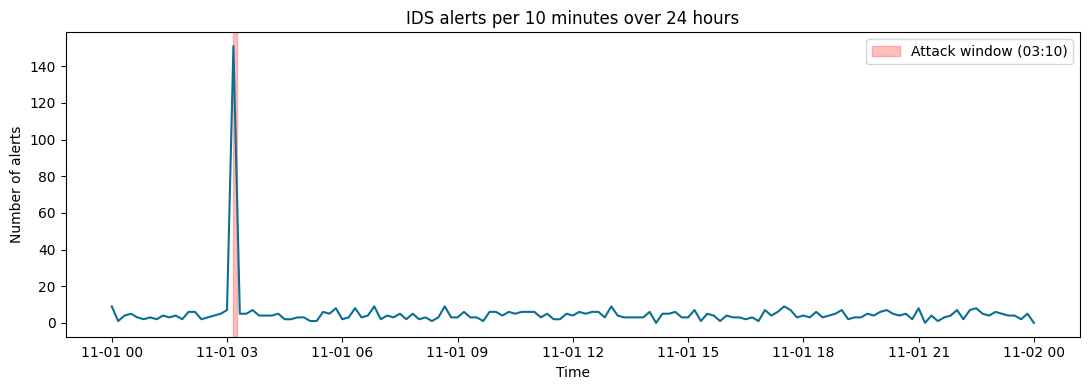

In [4]:
alerts["slot"] = alerts["timestamp"].dt.floor("10min")
per_slot = alerts.groupby("slot").size()

all_slots = pd.date_range(start, start + timedelta(hours=24), freq="10min")
per_slot = per_slot.reindex(all_slots, fill_value=0)

plt.figure(figsize=(11, 4))
plt.plot(per_slot.index, per_slot.values, color="#0B6E93")
plt.axvspan(attack_start, attack_start + timedelta(minutes=5),
            color="red", alpha=0.25, label="Attack window (03:10)")
plt.title("IDS alerts per 10 minutes over 24 hours")
plt.xlabel("Time")
plt.ylabel("Number of alerts")
plt.legend()
plt.tight_layout()
plt.savefig("01_alerts_timeline.png", dpi=150)
plt.show()

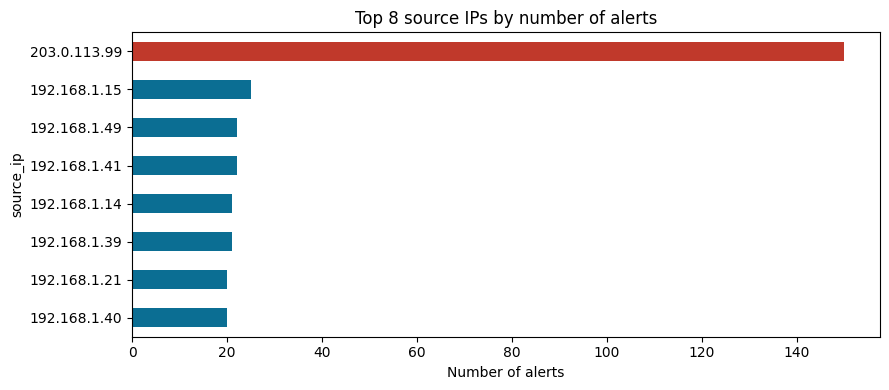

In [5]:
top_ips = alerts["source_ip"].value_counts().head(8)
colors = ["#C0392B" if ip == attacker else "#0B6E93" for ip in top_ips.index]

plt.figure(figsize=(9, 4))
top_ips.plot(kind="barh", color=colors)
plt.gca().invert_yaxis()          # biggest bar on top
plt.title("Top 8 source IPs by number of alerts")
plt.xlabel("Number of alerts")
plt.tight_layout()
plt.savefig("02_top_ips.png", dpi=150)
plt.show()

In [6]:
backup_ip = "192.168.1.5"
backup_start = start + timedelta(hours=14)

extra = []
for i in range(25):
    t = backup_start + timedelta(seconds=int(i * rng.uniform(5, 9)))
    extra.append((t, backup_ip, "Policy violation", "low", False))

cols5 = ["timestamp", "source_ip", "alert_type", "severity", "is_attack"]
alerts = pd.concat([alerts[cols5], pd.DataFrame(extra, columns=cols5)], ignore_index=True)
alerts = alerts.sort_values("timestamp").reset_index(drop=True)
print(alerts.shape)

(775, 5)


In [7]:
alerts["window"] = alerts["timestamp"].dt.floor("5min")
alerts["n_in_window"] = alerts.groupby(["source_ip", "window"])["alert_type"].transform("size")

THRESHOLD = 20
alerts["predicted_attack"] = alerts["n_in_window"] > THRESHOLD

print(pd.crosstab(alerts["is_attack"], alerts["predicted_attack"],
                  rownames=["Real"], colnames=["Predicted"]))

tp = (alerts["is_attack"] & alerts["predicted_attack"]).sum()      # attacks caught
fn = (alerts["is_attack"] & ~alerts["predicted_attack"]).sum()     # attacks missed
fp = (~alerts["is_attack"] & alerts["predicted_attack"]).sum()     # normal wrongly accused
tn = (~alerts["is_attack"] & ~alerts["predicted_attack"]).sum()    # normal correctly ignored

print("Detection rate (on attack data):", round(tp / (tp + fn), 3))
print("False alarm rate (on normal data):", round(fp / (fp + tn), 3))
print("Precision:", round(tp / (tp + fp), 3))

Predicted  False  True 
Real                   
False        600     25
True           0    150
Detection rate (on attack data): 1.0
False alarm rate (on normal data): 0.04
Precision: 0.857


In [8]:
results = []
for th in [5, 10, 20, 30, 40, 60, 100, 150]:
    pred = alerts["n_in_window"] > th
    tp = (alerts["is_attack"] & pred).sum();  fn = (alerts["is_attack"] & ~pred).sum()
    fp = (~alerts["is_attack"] & pred).sum(); tn = (~alerts["is_attack"] & ~pred).sum()
    results.append((th, round(tp/(tp+fn), 3), round(fp/(fp+tn), 3)))

table = pd.DataFrame(results, columns=["threshold", "detection_rate", "false_alarm_rate"])
print(table)

   threshold  detection_rate  false_alarm_rate
0          5             1.0              0.04
1         10             1.0              0.04
2         20             1.0              0.04
3         30             1.0              0.00
4         40             1.0              0.00
5         60             1.0              0.00
6        100             1.0              0.00
7        150             0.0              0.00


In [9]:
THRESHOLD = 40
alerts["predicted_attack"] = alerts["n_in_window"] > THRESHOLD

print(pd.crosstab(alerts["is_attack"], alerts["predicted_attack"],
                  rownames=["Real"], colnames=["Predicted"]))

tp = (alerts["is_attack"] & alerts["predicted_attack"]).sum()
fn = (alerts["is_attack"] & ~alerts["predicted_attack"]).sum()
fp = (~alerts["is_attack"] & alerts["predicted_attack"]).sum()
tn = (~alerts["is_attack"] & ~alerts["predicted_attack"]).sum()
print("Detection rate:", round(tp / (tp + fn), 3))
print("False alarm rate:", round(fp / (fp + tn), 3))
print("Precision:", round(tp / (tp + fp), 3))

Predicted  False  True 
Real                   
False        625      0
True           0    150
Detection rate: 1.0
False alarm rate: 0.0
Precision: 1.0
